# EDA

### Importación de librerías.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

### Importación de datos.

In [28]:
df = pd.read_excel('Base_Migracion_2009-2026jun.xlsx', sheet_name='Datos')
df.head(2)

,Año,Mes cod,Mes,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero
0,2009,1,Ene,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1.0
1,2009,1,Ene,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716.0


### Columna de datos.

In [29]:
df['Dia'] = 1
df['Fecha'] = pd.to_datetime(dict(year=df['Año'], month=df['Mes cod'], day=df['Dia']), errors='coerce')
df.drop(columns=['Año', 'Mes', 'Mes cod', 'Dia'], inplace=True)

### Comportamiento.

In [32]:
df_filtro = df[(df['Tipo de Viajero'].isin(['Excursionista', 'Turista']))]
df_anio = df_filtro.groupby('Fecha')['Viajero'].sum().round(0).astype(int)

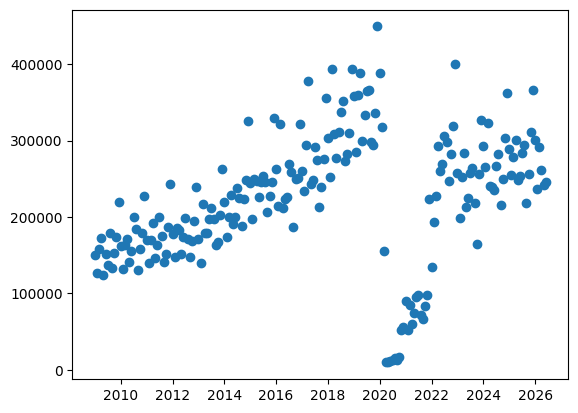

In [33]:
plt.scatter(x = df_anio.index, y = df_anio)

El comportamiento es a la alza, pero tiene el problema que en la pandemia hay una clara disminusión. la cual se separa de la tendencia que llevaba hasta antes de la pandemia.

### Países con mayor cantidad de viajeros.

In [35]:
df_paises = df_filtro.groupby('País')['Viajero'].sum().round(0).astype(int)
df_paises = df_paises.sort_values(ascending=False)
df_paises.head(3)

País
El Salvador                  14079136
Guatemala                    13870391
Estados Unidos de América     6965680
Name: Viajero, dtype: int64

### Regiones con mayor cantidad de viajeros.

In [37]:
df_regiones = df_filtro.groupby('Región')['Viajero'].sum().round(0).astype(int)
df_regiones = df_regiones.sort_values(ascending=False)
df_regiones.head(3)

Región
AMÉRICA DEL CENTRO    33283932
AMÉRICA DEL NORTE      9160810
EUROPA                 1848626
Name: Viajero, dtype: int64

### Vías de ingreso y fronteras más utilizadas.

In [38]:
df_vias = df_filtro.groupby('Vía')['Viajero'].sum().round(0).astype(int)
df_vias = df_vias.sort_values(ascending=False)
df_vias.head(3)

Vía
Terrestre    27592253
Aérea        19019419
Marítima       100241
Name: Viajero, dtype: int64

In [39]:
df_front = df_filtro.groupby('Frontera')['Viajero'].sum().round(0).astype(int)
df_front = df_front.sort_values(ascending=False)
df_front.head(3)

Frontera
01 La Aurora        18989985
07 Valle Nuevo      10143045
09 San Cristóbal     4183632
Name: Viajero, dtype: int64

### Análisis de valores faltantes, duplicados y valores atípicos.

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161036 entries, 0 to 161035
Data columns (total 11 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   Vía                    161036 non-null  object        
 1   Frontera               161036 non-null  object        
 2   País                   161036 non-null  object        
 3   Región                 161036 non-null  object        
 4   Región dos             161036 non-null  object        
 5   Regiones OMT           161036 non-null  object        
 6   MCEO                   161036 non-null  object        
 7   Agrupación Residencia  161036 non-null  object        
 8   Tipo de Viajero        161036 non-null  object        
 9   Viajero                161036 non-null  float64       
 10  Fecha                  161036 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), object(9)
memory usage: 13.5+ MB


No hay valores faltantes.

In [45]:
print('Hay', int(df.duplicated().sum()), 'valores duplicados.')

Hay 0 valores duplicados.


In [46]:
df.describe()

,Viajero,Fecha
count,161036.000000,161036
mean,324.697193,2016-06-19 22:24:29.365856256
min,0.000000,2009-01-01 00:00:00
25%,2.000000,2012-10-01 00:00:00
50%,7.000000,2016-03-01 00:00:00
75%,38.891667,2019-07-01 00:00:00
max,92336.035067,2026-06-01 00:00:00
std,2387.745140,NaN


Hay valores atípicos, pero puede deberse a los pasíses donde mayor visitas se tienen.

### Estadísticas descriptivas y visualizaciones con su respectiva interpretación.

{'whiskers': [<matplotlib.lines.Line2D at 0x20a7fd7afd0>,
 'caps': [<matplotlib.lines.Line2D at 0x20a7fd7b250>,
 'boxes': [<matplotlib.lines.Line2D at 0x20a7fd7ae90>],
 'medians': [<matplotlib.lines.Line2D at 0x20a7fd7b4d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x20a7fd7b610>],
 'means': []}

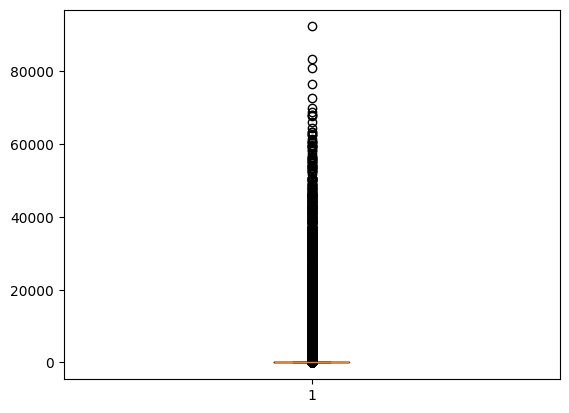

In [49]:
plt.boxplot(df['Viajero'])

Se puede observar una alta cantidad de atípicos, eso debido a los países que más nos visitan.

In [50]:
df.describe()

,Viajero,Fecha
count,161036.000000,161036
mean,324.697193,2016-06-19 22:24:29.365856256
min,0.000000,2009-01-01 00:00:00
25%,2.000000,2012-10-01 00:00:00
50%,7.000000,2016-03-01 00:00:00
75%,38.891667,2019-07-01 00:00:00
max,92336.035067,2026-06-01 00:00:00
std,2387.745140,NaN


La mayoría de países tienen poca relevancia en el turismo de Guatemala, esto se demuestra con la gran cantidad de atípicos.